**Hrusikesh Nishank**
**Roll No. P26CS0003**
**MACHINE LEARNING ASSIGNMENT 2**

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

#numeric characters from my roll number P26CS0003
seed = 260003
rng = np.random.default_rng(seed)


In [19]:
#load the OLivetti Faces dataset
faces = fetch_olivetti_faces()

X = faces.images
y = faces.target

print("images shape:", X.shape)
print("labels shape:", y.shape)
print("number of unique identities:", len(np.unique(y)))

images shape: (400, 64, 64)
labels shape: (400,)
number of unique identities: 40


In [ ]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

In [20]:
#creating the fixed 6/2/2 split as asked
train_idx = []
val_idx = []
test_idx = []

for person in range(40):
    person_idx = np.where(y == person)[0]
    person_idx = rng.permutation(person_idx)

    train_idx.extend(person_idx[:6])
    val_idx.extend(person_idx[6:8])
    test_idx.extend(person_idx[8:10])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

print("Train images:", len(train_idx))
print("Val images:", len(val_idx))
print("Test images:", len(test_idx))


#saving the split 
np.savez(
    "data/olivetti_split_seed260003.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Split saved.")

Train images: 240
Val images: 80
Test images: 80
Split saved.


In [21]:
#usign rae flattened pixels only, creating the train, val and test data

X_train = X[train_idx].reshape(len(train_idx), -1)
X_val = X[val_idx].reshape(len(val_idx), -1)
X_test = X[test_idx].reshape(len(test_idx), -1)

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (240, 4096)
X_val: (80, 4096)
X_test: (80, 4096)


In [22]:
#creating the masked robustness test set for later use
X_test_images = X[test_idx].copy()

X_test_masked_images = X_test_images.copy()
X_test_masked_images[:, 24:40, 24:40] = 0

X_test_masked = X_test_masked_images.reshape(len(test_idx), -1)

print("Clean test shape:", X_test.shape)
print("Masked test shape:", X_test_masked.shape)

Clean test shape: (80, 4096)
Masked test shape: (80, 4096)


**QUESTION 1: Decision tree baseline and bagging from scratch**

**Part A**

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [25]:
#training all tree settings
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

tree_results = []
tree_models = {}

for depth in depth_values:
    for min_leaf in leaf_values:

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=seed
        )

        tree.fit(X_train, y_train)

        train_acc = accuracy_score(y_train, tree.predict(X_train))
        val_acc = accuracy_score(y_val, tree.predict(X_val))

        tree_results.append([
            depth,
            min_leaf,
            train_acc,
            val_acc
        ])

        tree_models[(depth, min_leaf)] = tree

In [26]:
#printing the valuidation search results
print("Depth   Min Leaf   Train Acc   Val Acc")

for row in tree_results:
    depth, min_leaf, train_acc, val_acc = row

    print(
        f"{str(depth):>5}   "
        f"{min_leaf:>8}   "
        f"{train_acc:.4f}      "
        f"{val_acc:.4f}"
    )

Depth   Min Leaf   Train Acc   Val Acc
    2          1   0.0750      0.0750
    2          2   0.0750      0.0750
    2          4   0.0750      0.0750
    4          1   0.1250      0.1250
    4          2   0.1250      0.1250
    4          4   0.1250      0.1250
    8          1   0.2250      0.2000
    8          2   0.2250      0.2000
    8          4   0.2250      0.2000
   16          1   0.4250      0.3000
   16          2   0.4250      0.3000
   16          4   0.4250      0.3000
 None          1   1.0000      0.5750
 None          2   0.9750      0.5375
 None          4   0.9750      0.5750


In [27]:
#selecting the best setting using val accuracy
best_row = max(tree_results, key=lambda x: x[3])

best_depth = best_row[0]
best_min_leaf = best_row[1]

frozen_tree = tree_models[(best_depth, best_min_leaf)]

print("Selected max_depth:", best_depth)
print("Selected min_samples_leaf:", best_min_leaf)
print("Validation accuracy:", round(best_row[3], 4))

Selected max_depth: None
Selected min_samples_leaf: 1
Validation accuracy: 0.575


In [31]:
#final baseline results
train_pred = frozen_tree.predict(X_train)
val_pred = frozen_tree.predict(X_val)
test_pred = frozen_tree.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Train accuracy:", round(train_acc, 4))
print("Val accuracy:", round(val_acc, 4))
print("Test accuracy:", round(test_acc, 4))

Train accuracy: 1.0
Val accuracy: 0.575
Test accuracy: 0.6875


In [32]:
#leaf statistics
tree_info = frozen_tree.tree_

leaf_nodes = np.where(tree_info.children_left == -1)[0]
leaf_samples = tree_info.n_node_samples[leaf_nodes]

num_leaves = len(leaf_nodes)
mean_samples = leaf_samples.mean()
single_sample_fraction = np.mean(leaf_samples == 1)

print("Number of leaves:", num_leaves)
print("Mean samples per leaf:", round(mean_samples, 4))
print("Fraction of single sample leaves:", round(single_sample_fraction, 4))

Number of leaves: 46
Mean samples per leaf: 5.2174
Fraction of single sample leaves: 0.1304


In [34]:
#saving results
import pandas as pd
search_table = pd.DataFrame(
    tree_results,
    columns=[
        "max_depth",
        "min_samples_leaf",
        "train_accuracy",
        "validation_accuracy"
    ]
)

search_table.to_csv(
    "results/q1a_tree_search.csv",
    index=False
)

final_tree_result = pd.DataFrame([{
    "max_depth": best_depth,
    "min_samples_leaf": best_min_leaf,
    "train_accuracy": train_acc,
    "validation_accuracy": val_acc,
    "test_accuracy": test_acc,
    "number_of_leaves": num_leaves,
    "mean_samples_per_leaf": mean_samples,
    "single_sample_leaf_fraction": single_sample_fraction
}])

final_tree_result.to_csv(
    "results/q1a_frozen_tree.csv",
    index=False
)


**Part b**

In [35]:
#training the bagged trees

B_values = [1, 5, 10, 25, 50, 100, 200]

n_train = len(X_train)

bag_trees = []
bootstrap_indices = []
distinct_counts = []

for i in range(max(B_values)):

    boot_idx = rng.choice(
        n_train,
        size=n_train,
        replace=True
    )

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed
    )

    tree.fit(
        X_train[boot_idx],
        y_train[boot_idx]
    )

    bag_trees.append(tree)
    bootstrap_indices.append(boot_idx)
    distinct_counts.append(len(np.unique(boot_idx)))

print("Bagged trees trained:", len(bag_trees))

Bagged trees trained: 200


In [36]:
#majorityvote function
def bagging_predict(trees, X):

    predictions = np.array([
        tree.predict(X) for tree in trees
    ])

    final_predictions = []

    for i in range(X.shape[0]):
        votes = np.bincount(predictions[:, i], minlength=40)
        final_predictions.append(np.argmax(votes))

    return np.array(final_predictions)


In [37]:
#evaluating every required B
bagging_results = []

for B in B_values:

    trees = bag_trees[:B]

    train_pred = bagging_predict(trees, X_train)
    val_pred = bagging_predict(trees, X_val)
    test_pred = bagging_predict(trees, X_test)

    train_acc_bag = accuracy_score(y_train, train_pred)
    val_acc_bag = accuracy_score(y_val, val_pred)
    test_acc_bag = accuracy_score(y_test, test_pred)

    avg_distinct = np.mean(distinct_counts[:B])

    bagging_results.append([
        B,
        train_acc_bag,
        val_acc_bag,
        test_acc_bag,
        avg_distinct
    ])

In [38]:
#printing the results
print("B     Train Acc   Val Acc   Test Acc   Avg Distinct")

for row in bagging_results:

    B, train_acc_bag, val_acc_bag, test_acc_bag, avg_distinct = row

    print(
        f"{B:<5} "
        f"{train_acc_bag:.4f}      "
        f"{val_acc_bag:.4f}    "
        f"{test_acc_bag:.4f}     "
        f"{avg_distinct:.2f}"
    )

B     Train Acc   Val Acc   Test Acc   Avg Distinct
1     0.8208      0.4250    0.3875     156.00
5     0.9875      0.6250    0.5500     151.20
10    1.0000      0.7500    0.7125     152.70
25    1.0000      0.8250    0.7750     152.16
50    1.0000      0.8500    0.8125     150.86
100   1.0000      0.8750    0.8250     151.64
200   1.0000      0.8875    0.8625     151.79


In [39]:
#compoaring with the theoritical distinct
theoretical_distinct = n_train * (
    1 - (1 - 1/n_train) ** n_train
)

print("training set size:", n_train)
print("Theoretical distinctexamples:", round(theoretical_distinct, 2))
print("Expected fraction:", round(theoretical_distinct / n_train, 4))

training set size: 240
Theoretical distinctexamples: 151.89
Expected fraction: 0.6329


In [42]:
#saving the results of q1b
bagging_table = pd.DataFrame(
    bagging_results,
    columns=[
        "B",
        "train_accuracy",
        "validation_accuracy",
        "test_accuracy",
        "avg_distinct_examples"
    ]
)

bagging_table["theoretical_distinct"] = theoretical_distinct

bagging_table.to_csv(
    "results/q1b_bagging.csv",
    index=False
)


**Part C**

In [43]:
#predictions from individual trees

train_tree_preds = np.array([
    tree.predict(X_train) for tree in bag_trees
])

val_tree_preds = np.array([
    tree.predict(X_val) for tree in bag_trees
])

print("trainprediction matrix:", train_tree_preds.shape)
print("Val prediction matrix:", val_tree_preds.shape)

trainprediction matrix: (200, 240)
Val prediction matrix: (200, 80)


In [44]:
#outofbag masks, if the tree was not included in that tree's bootstrap sample

oob_mask = np.ones((len(bag_trees), n_train), dtype=bool)

for i, boot_idx in enumerate(bootstrap_indices):
    oob_mask[i, np.unique(boot_idx)] = False

In [45]:
#defining the oob accuracy function
def get_oob_accuracy(B):

    correct = 0
    total = 0

    for i in range(n_train):

        available = oob_mask[:B, i]

        if np.sum(available) == 0:
            continue

        preds = train_tree_preds[:B, i][available]

        votes = np.bincount(preds, minlength=40)
        final_pred = np.argmax(votes)

        if final_pred == y_train[i]:
            correct += 1

        total += 1

    return correct / total

In [46]:
#pairwise disagreement function
def get_disagreement(predictions):

    B = predictions.shape[0]

    if B == 1:
        return 0.0

    values = []

    for i in range(B):
        for j in range(i + 1, B):

            disagreement = np.mean(
                predictions[i] != predictions[j]
            )

            values.append(disagreement)

    return np.mean(values)

In [47]:
#defining the mean vote margin fucntion
def get_vote_margin(predictions):

    B = predictions.shape[0]
    margins = []

    for i in range(predictions.shape[1]):

        votes = np.bincount(
            predictions[:, i],
            minlength=40
        )

        sorted_votes = np.sort(votes)[::-1]

        winner = sorted_votes[0] / B
        runner_up = sorted_votes[1] / B

        margins.append(winner - runner_up)

    return np.mean(margins)

In [49]:
#calculating the three metrics
q1c_results = []

for B in B_values:

    oob_acc = get_oob_accuracy(B)

    val_preds_B = val_tree_preds[:B]

    disagreement = get_disagreement(val_preds_B)
    vote_margin = get_vote_margin(val_preds_B)

    q1c_results.append([
        B,
        oob_acc,
        disagreement,
        vote_margin
    ])

#printing the results
print("B     OOB Acc    Disagreement    Vote Margin")

for row in q1c_results:

    B, oob_acc, disagreement, vote_margin = row

    print(
        f"{B:<5} "
        f"{oob_acc:.4f}     "
        f"{disagreement:.4f}          "
        f"{vote_margin:.4f}"
    )

B     OOB Acc    Disagreement    Vote Margin
1     0.4881     0.0000          1.0000
5     0.3674     0.7775          0.2575
10    0.4346     0.7872          0.2450
25    0.6208     0.7928          0.2630
50    0.7042     0.7920          0.2673
100   0.7542     0.7942          0.2729
200   0.7792     0.7935          0.2776


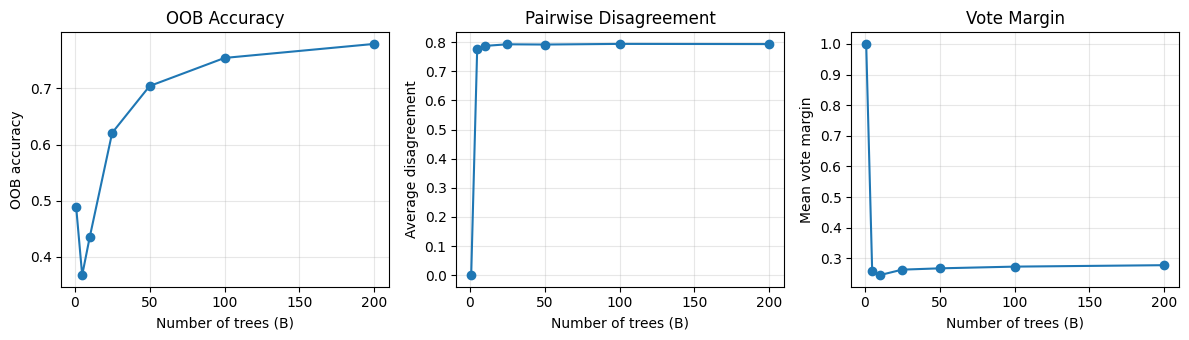

In [50]:
#plotting q1c

B_plot = [row[0] for row in q1c_results]
oob_plot = [row[1] for row in q1c_results]
disagreement_plot = [row[2] for row in q1c_results]
margin_plot = [row[3] for row in q1c_results]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))

ax[0].plot(B_plot, oob_plot, marker="o")
ax[0].set_xlabel("Number of trees (B)")
ax[0].set_ylabel("OOB accuracy")
ax[0].set_title("OOB Accuracy")
ax[0].grid(alpha=0.3)

ax[1].plot(B_plot, disagreement_plot, marker="o")
ax[1].set_xlabel("Number of trees (B)")
ax[1].set_ylabel("Average disagreement")
ax[1].set_title("Pairwise Disagreement")
ax[1].grid(alpha=0.3)

ax[2].plot(B_plot, margin_plot, marker="o")
ax[2].set_xlabel("Number of trees (B)")
ax[2].set_ylabel("Mean vote margin")
ax[2].set_title("Vote Margin")
ax[2].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/q1c_bagging_metrics.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [51]:
#selecting the final ensemble size using the validatioon accuracies from q1b
best_bag_row = max(
    bagging_results,
    key=lambda row: row[2]
)

final_B = best_bag_row[0]
final_val_acc = best_bag_row[2]

final_bag_trees = bag_trees[:final_B]

print("Final ensemble size:", final_B)
print("Val accuracy:", round(final_val_acc, 4))

Final ensemble size: 200
Val accuracy: 0.8875


In [53]:
#saving the rsults
q1c_table = pd.DataFrame(
    q1c_results,
    columns=[
        "B",
        "oob_accuracy",
        "pairwise_disagreement",
        "mean_vote_margin"
    ]
)

q1c_table.to_csv(
    "results/q1c_bagging_diagnostics.csv",
    index=False
)


**Part d**

In [54]:
#bagging prediction with vote confidence

def bag_predict_with_confidence(trees, X):

    all_preds = np.array([
        tree.predict(X) for tree in trees
    ])

    final_preds = []
    confidences = []
    vote_counts = []

    for i in range(X.shape[0]):

        votes = np.bincount(
            all_preds[:, i],
            minlength=40
        )

        pred = np.argmax(votes)

        final_preds.append(pred)
        confidences.append(votes[pred] / len(trees))
        vote_counts.append(votes)

    return (
        np.array(final_preds),
        np.array(confidences),
        np.array(vote_counts)
    )

In [55]:
#compiling singletree resutls
# single tree results

tree_clean_pred = frozen_tree.predict(X_test)
tree_masked_pred = frozen_tree.predict(X_test_masked)

tree_clean_prob = frozen_tree.predict_proba(X_test)
tree_masked_prob = frozen_tree.predict_proba(X_test_masked)

tree_clean_conf = tree_clean_prob.max(axis=1)
tree_masked_conf = tree_masked_prob.max(axis=1)

tree_clean_acc = accuracy_score(y_test, tree_clean_pred)
tree_masked_acc = accuracy_score(y_test, tree_masked_pred)

print("Single tree")
print("Clean accuracy :", round(tree_clean_acc, 4))
print("Clean confidence:", round(tree_clean_conf.mean(), 4))
print("Masked accuracy:", round(tree_masked_acc, 4))
print("Masked confidence:", round(tree_masked_conf.mean(), 4))

Single tree
Clean accuracy : 0.6875
Clean confidence: 1.0
Masked accuracy: 0.3375
Masked confidence: 1.0


In [57]:
#final  bagged model results

bag_clean_pred, bag_clean_conf, bag_clean_votes = bag_predict_with_confidence(
    final_bag_trees,
    X_test
)

bag_masked_pred, bag_masked_conf, bag_masked_votes = bag_predict_with_confidence(
    final_bag_trees,
    X_test_masked
)

bag_clean_acc = accuracy_score(y_test, bag_clean_pred)
bag_masked_acc = accuracy_score(y_test, bag_masked_pred)

print("Bagged model")
print("Clean accuracy:", round(bag_clean_acc, 4))
print("Clean confidence:", round(bag_clean_conf.mean(), 4))
print("Masked accuracy:", round(bag_masked_acc, 4))
print("Masked confidence:", round(bag_masked_conf.mean(), 4))

Bagged model
Clean accuracy: 0.8625
Clean confidence: 0.4178
Masked accuracy: 0.5625
Masked confidence: 0.312


In [59]:
#presenting the comparison and saving them
comparison = pd.DataFrame([
    ["Single Tree", "Clean", tree_clean_acc, tree_clean_conf.mean()],
    ["Single Tree", "Masked", tree_masked_acc, tree_masked_conf.mean()],
    ["Bagging", "Clean", bag_clean_acc, bag_clean_conf.mean()],
    ["Bagging", "Masked", bag_masked_acc, bag_masked_conf.mean()]
],
columns=[
    "Model",
    "Test Set",
    "Accuracy",
    "Mean Confidence"
])


comparison.to_csv(
    "results/q1d_clean_masked_comparison.csv",
    index=False
)

In [60]:
#finding the required faced from the clean test set
bag_corrects_tree = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred == y_test)
)[0]

both_wrong = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred != y_test)
)[0]

print("Bagging corrects tree:", len(bag_corrects_tree))
print("Both wrong:", len(both_wrong))

print("First two corrected:", bag_corrects_tree[:2])
print("First two both wrong:", both_wrong[:2])

Bagging corrects tree: 19
Both wrong: 6
First two corrected: [2 6]
First two both wrong: [0 5]


In [61]:
#showing the prediction adn the vote counts
corrected_cases = bag_corrects_tree[:2]
wrong_cases = both_wrong[:2]

selected_cases = list(corrected_cases) + list(wrong_cases)

for idx in selected_cases:

    true_class = y_test[idx]
    tree_class = tree_clean_pred[idx]
    bag_class = bag_clean_pred[idx]

    votes = bag_clean_votes[idx]

    print("\nTest index:", idx)
    print("True class:", true_class)
    print("Tree prediction:", tree_class)

    print(
        "Bagging prediction:",
        bag_class,
        "- votes:",
        votes[bag_class]
    )

    print(
        "Votes for true class:",
        votes[true_class]
    )

    print(
        "Votes for tree prediction:",
        votes[tree_class]
    )


Test index: 2
True class: 1
Tree prediction: 16
Bagging prediction: 1 - votes: 56
Votes for true class: 56
Votes for tree prediction: 1

Test index: 6
True class: 3
Tree prediction: 20
Bagging prediction: 3 - votes: 43
Votes for true class: 43
Votes for tree prediction: 34

Test index: 0
True class: 0
Tree prediction: 26
Bagging prediction: 26 - votes: 58
Votes for true class: 43
Votes for tree prediction: 58

Test index: 5
True class: 2
Tree prediction: 20
Bagging prediction: 20 - votes: 31
Votes for true class: 17
Votes for tree prediction: 31


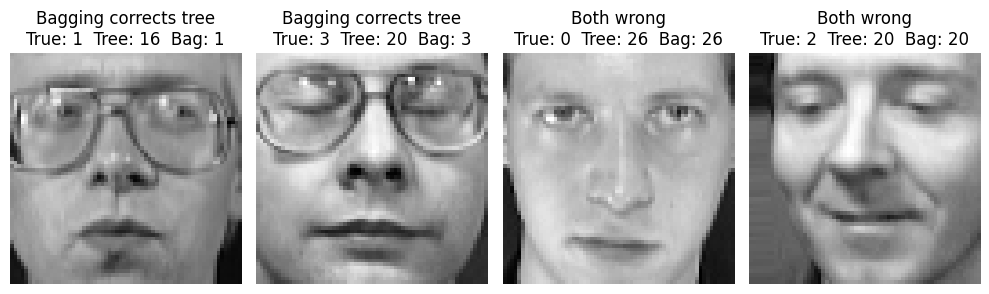

In [62]:
#the correct an th wrong faces
fig, ax = plt.subplots(1, 4, figsize=(10, 3))

titles = [
    "Bagging corrects tree",
    "Bagging corrects tree",
    "Both wrong",
    "Both wrong"
]

for i, idx in enumerate(selected_cases):

    ax[i].imshow(
        X_test[idx].reshape(64, 64),
        cmap="gray"
    )

    ax[i].set_title(
        f"{titles[i]}\n"
        f"True: {y_test[idx]}  "
        f"Tree: {tree_clean_pred[idx]}  "
        f"Bag: {bag_clean_pred[idx]}"
    )

    ax[i].axis("off")

plt.tight_layout()

plt.savefig(
    "figures/q1d_example_faces.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [63]:
#saving the dtails
case_rows = []

for idx in selected_cases:

    case_type = (
        "Bagging corrects tree"
        if idx in corrected_cases
        else "Both wrong"
    )

    case_rows.append([
        idx,
        case_type,
        y_test[idx],
        tree_clean_pred[idx],
        bag_clean_pred[idx],
        bag_clean_votes[idx][bag_clean_pred[idx]],
        bag_clean_votes[idx][y_test[idx]]
    ])

case_table = pd.DataFrame(
    case_rows,
    columns=[
        "test_index",
        "case_type",
        "true_class",
        "tree_prediction",
        "bagging_prediction",
        "winning_votes",
        "true_class_votes"
    ]
)

case_table.to_csv(
    "results/q1d_example_cases.csv",
    index=False
)

**QUESTION 2: Multiclass boosting from scratch**

**Part A**

In [64]:
#small three class toy example
X_toy = np.array([
    [0.0], [0.5], [1.0],
    [2.0], [2.5], [3.0],
    [4.0], [4.5], [5.0]
])

y_toy = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])

K = 3
n = len(y_toy)

weights = np.ones(n) / n

print("Initial weights:")
print(np.round(weights, 4))


Initial weights:
[0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]


In [65]:
#one samme round
weak_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=seed
)

weak_tree.fit(
    X_toy,
    y_toy,
    sample_weight=weights
)

pred = weak_tree.predict(X_toy)

wrong = pred != y_toy

error = np.sum(weights[wrong])

random_limit = 1 - (1 / K)

print("Predictions:", pred)
print("Weighted error:", round(error, 4))

Predictions: [0 0 0 1 1 1 1 1 1]
Weighted error: 0.3333


In [69]:
if error >= random_limit:
    print("Weak learner not better than random prediction.")
else:
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    new_weights = weights * np.exp(alpha * wrong)
    new_weights = new_weights / new_weights.sum()

    print("alpha:", round(alpha, 4))
    print("Updated weights")
    print(np.round(new_weights, 4))

alpha: 1.3863
Updated weights
[0.0556 0.0556 0.0556 0.0556 0.0556 0.0556 0.2222 0.2222 0.2222]


In [70]:
new_weights = weights * np.exp(alpha * wrong)
new_weights = new_weights / new_weights.sum()

In [73]:
toy_log = pd.DataFrame({
    "true_class": y_toy,
    "initial_weight": weights,
    "prediction": pred,
    "wrong": wrong.astype(int),
    "updated_weight": new_weights
})
display(toy_log)
toy_log.to_csv(
    "results/q2a_samme_round.csv",
    index=False
)

,true_class,initial_weight,prediction,wrong,updated_weight
0,0,0.111111,0,0,0.055556
1,0,0.111111,0,0,0.055556
2,0,0.111111,0,0,0.055556
3,1,0.111111,1,0,0.055556
4,1,0.111111,1,0,0.055556
5,1,0.111111,1,0,0.055556
6,2,0.111111,1,1,0.222222
7,2,0.111111,1,1,0.222222
8,2,0.111111,1,1,0.222222


**Part B**

In [74]:
#samme training function
def train_samme(X, y, depth, rounds):

    n = len(y)
    K = len(np.unique(y))

    weights = np.ones(n) / n

    trees = []
    alphas = []

    errors = []
    max_weights = []
    top10_weights = []

    random_limit = 1 - (1 / K)

    for t in range(rounds):

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        tree.fit(
            X,
            y,
            sample_weight=weights
        )

        pred = tree.predict(X)
        wrong = pred != y

        error = np.sum(weights[wrong])

        # weak learner must be better than random multiclass prediction
        if error >= random_limit:
            print("Stopped at round", t + 1, "- weak learner not better than random")
            break

        error_safe = max(error, 1e-12)

        alpha = (
            np.log((1 - error_safe) / error_safe)
            + np.log(K - 1)
        )

        # same update rule as we did previosuly
        weights = weights * np.exp(alpha * wrong)
        weights = weights / weights.sum()

        trees.append(tree)
        alphas.append(alpha)

        errors.append(error)
        max_weights.append(weights.max())
        top10_weights.append(
            np.sort(weights)[-10:].sum()
        )

    return trees, np.array(alphas), errors, max_weights, top10_weights

In [75]:
#weighted vote prediction
def samme_predict(trees, alphas, X):

    scores = np.zeros((len(X), 40))

    for tree, alpha in zip(trees, alphas):

        pred = tree.predict(X)

        for i in range(len(X)):
            scores[i, pred[i]] += alpha

    return np.argmax(scores, axis=1)

In [76]:
#training the 4 depths
depths = [1, 2, 3, 4]

samme_models = {}

for depth in depths:

    print("training depth:", depth)

    model = train_samme(
        X_train,
        y_train,
        depth,
        100
    )

    samme_models[depth] = model

training depth: 1
training depth: 2
training depth: 3
training depth: 4


In [77]:
#evaluating 10, 25, 50 and 100 rounds
round_values = [10, 25, 50, 100]

boosting_results = []

for depth in depths:

    trees, alphas, errors, max_w, top10_w = samme_models[depth]

    for rounds in round_values:

        use_trees = trees[:rounds]
        use_alphas = alphas[:rounds]

        train_pred = samme_predict(
            use_trees,
            use_alphas,
            X_train
        )

        val_pred = samme_predict(
            use_trees,
            use_alphas,
            X_val
        )

        train_acc_boost = accuracy_score(
            y_train,
            train_pred
        )

        val_acc_boost = accuracy_score(
            y_val,
            val_pred
        )

        boosting_results.append([
            depth,
            rounds,
            train_acc_boost,
            val_acc_boost
        ])

In [78]:
#printing the above depth and rounds table
print("Depth   Rounds   Train Acc   Val Acc")

for row in boosting_results:

    depth, rounds, train_acc_boost, val_acc_boost = row

    print(
        f"{depth:<7} "
        f"{rounds:<8} "
        f"{train_acc_boost:.4f}      "
        f"{val_acc_boost:.4f}"
    )

#slecting the depth and rounds using val accuracy only
best_boost_row = max(
    boosting_results,
    key=lambda row: row[3]
)

best_boost_depth = best_boost_row[0]
best_boost_rounds = best_boost_row[1]

print("Selected depth", best_boost_depth)
print("Selected round:", best_boost_rounds)
print("val accuracy:", round(best_boost_row[3], 4))

Depth   Rounds   Train Acc   Val Acc
1       10       0.0500      0.0500
1       25       0.0917      0.0750
1       50       0.0667      0.0625
1       100      0.1083      0.0750
2       10       0.1333      0.1125
2       25       0.1875      0.1750
2       50       0.2125      0.1375
2       100      0.4250      0.2250
3       10       0.1333      0.0875
3       25       0.2833      0.2000
3       50       0.2875      0.1625
3       100      0.5667      0.2625
4       10       0.3417      0.2125
4       25       0.5417      0.2250
4       50       0.9292      0.4000
4       100      0.9917      0.5125
Selected depth 4
Selected round: 100
val accuracy: 0.5125


In [80]:
#freezing selected samme model
selected_model = samme_models[best_boost_depth]

all_trees = selected_model[0]
all_alphas = selected_model[1]
all_errors = selected_model[2]
all_max_weights = selected_model[3]
all_top10_weights = selected_model[4]

boost_trees = all_trees[:best_boost_rounds]
boost_alphas = all_alphas[:best_boost_rounds]

boost_errors = all_errors[:best_boost_rounds]
boost_max_weights = all_max_weights[:best_boost_rounds]
boost_top10_weights = all_top10_weights[:best_boost_rounds]

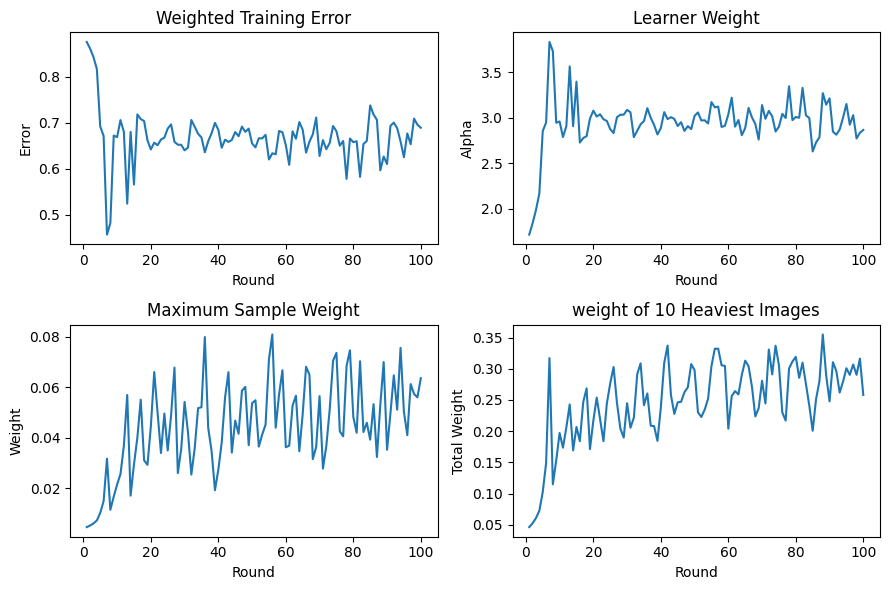

In [81]:
#plotting the four quantities 
round_axis = np.arange(
    1,
    len(boost_alphas) + 1
)

fig, ax = plt.subplots(
    2, 2,
    figsize=(9, 6)
)

ax[0, 0].plot(round_axis, boost_errors)
ax[0, 0].set_title("Weighted Training Error")
ax[0, 0].set_xlabel("Round")
ax[0, 0].set_ylabel("Error")
ax[0, 1].plot(round_axis, boost_alphas)
ax[0, 1].set_title("Learner Weight")
ax[0, 1].set_xlabel("Round")
ax[0, 1].set_ylabel("Alpha")
ax[1, 0].plot(round_axis, boost_max_weights)
ax[1, 0].set_title("Maximum Sample Weight")
ax[1, 0].set_xlabel("Round")
ax[1, 0].set_ylabel("Weight")
ax[1, 1].plot(round_axis, boost_top10_weights)
ax[1, 1].set_title("weight of 10 Heaviest Images")
ax[1, 1].set_xlabel("Round")
ax[1, 1].set_ylabel("Total Weight")

plt.tight_layout()

plt.savefig(
    "figures/q2b_samme_training.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [82]:
#saving the search results and the selected model's round by round history
boosting_table = pd.DataFrame(
    boosting_results,
    columns=[
        "depth",
        "rounds",
        "train_accuracy",
        "validation_accuracy"
    ]
)

boosting_table.to_csv(
    "results/q2b_samme_search.csv",
    index=False
)

display(boosting_table)

boost_history = pd.DataFrame({
    "round": round_axis,
    "weighted_error": boost_errors,
    "alpha": boost_alphas,
    "max_sample_weight": boost_max_weights,
    "top10_total_weight": boost_top10_weights
})

boost_history.to_csv(
    "results/q2b_samme_history.csv",
    index=False
)

boost_history

,depth,rounds,train_accuracy,validation_accuracy
0,1,10,0.050000,0.0500
1,1,25,0.091667,0.0750
2,1,50,0.066667,0.0625
3,1,100,0.108333,0.0750
4,2,10,0.133333,0.1125
5,2,25,0.187500,0.1750
6,2,50,0.212500,0.1375
7,2,100,0.425000,0.2250
8,3,10,0.133333,0.0875
9,3,25,0.283333,0.2000


,round,weighted_error,alpha,max_sample_weight,top10_total_weight
0,1,0.875000,1.717651,0.004643,0.046429
1,2,0.860714,1.842326,0.005259,0.052593
2,3,0.842220,1.988723,0.006088,0.060885
3,4,0.816512,2.170671,0.007270,0.072703
4,5,0.691924,2.854432,0.010245,0.102447
...,...,...,...,...,...
95,96,0.676735,2.924756,0.041041,0.290216
96,97,0.653313,3.029928,0.061249,0.306870
97,98,0.708821,2.773899,0.057361,0.290320
98,99,0.695724,2.836542,0.056008,0.316314


**Part c**

In [83]:
#bagging comparison with training time
import time

sizes = [25, 50, 100]
compare_results = []

rng_compare = np.random.default_rng(seed)
bag_compare = []

start = time.perf_counter()

for i in range(100):

    idx = rng_compare.choice(n_train, n_train, replace=True)

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed + i
    )

    tree.fit(X_train[idx], y_train[idx])
    bag_compare.append(tree)

    if i + 1 in sizes:

        train_time = time.perf_counter() - start
        B = i + 1

        train_pred = bagging_predict(bag_compare, X_train)
        val_pred = bagging_predict(bag_compare, X_val)
        test_pred = bagging_predict(bag_compare, X_test)

        compare_results.append([
            "Bagging", B,
            accuracy_score(y_train, train_pred),
            accuracy_score(y_val, val_pred),
            accuracy_score(y_test, test_pred),
            train_time
        ])

In [84]:
#boosting comaprison with trraining time
boost_compare = []
boost_alpha = []

weights = np.ones(n_train) / n_train
K = 40

start = time.perf_counter()

for t in range(100):

    tree = DecisionTreeClassifier(
        max_depth=best_boost_depth,
        random_state=seed + t
    )

    tree.fit(X_train, y_train, sample_weight=weights)

    pred = tree.predict(X_train)
    wrong = pred != y_train
    error = np.sum(weights[wrong])

    if error >= 1 - 1/K:
        break

    alpha = np.log((1-error)/error) + np.log(K-1)

    weights = weights * np.exp(alpha * wrong)
    weights = weights / weights.sum()

    boost_compare.append(tree)
    boost_alpha.append(alpha)

    if t + 1 in sizes:

        train_time = time.perf_counter() - start
        B = t + 1

        train_pred = samme_predict(boost_compare, boost_alpha, X_train)
        val_pred = samme_predict(boost_compare, boost_alpha, X_val)
        test_pred = samme_predict(boost_compare, boost_alpha, X_test)

        compare_results.append([
            "Boosting", B,
            accuracy_score(y_train, train_pred),
            accuracy_score(y_val, val_pred),
            accuracy_score(y_test, test_pred),
            train_time
        ])

In [86]:
#comparison between the two
compare_table = pd.DataFrame(
    compare_results,
    columns=[
        "model", "learners",
        "train_accuracy",
        "validation_accuracy",
        "test_accuracy",
        "training_time"
    ]
)

display(compare_table)

compare_table.to_csv(
    "results/q2c_bagging_vs_boosting.csv",
    index=False
)

,model,learners,train_accuracy,validation_accuracy,test_accuracy,training_time
0,Bagging,25,1.000000,0.8125,0.8250,106.876215
1,Bagging,50,1.000000,0.8625,0.8375,208.420806
2,Bagging,100,1.000000,0.9000,0.8625,418.283564
3,Boosting,25,0.541667,0.2250,0.2375,39.555967
4,Boosting,50,0.929167,0.4000,0.3625,77.720220
5,Boosting,100,0.991667,0.5125,0.4625,154.291638


In [89]:
#finding the training sample with the largest weight
weights = np.ones(n_train) / n_train

weight_history = []
prediction_history = []

for tree, alpha in zip(boost_trees, boost_alphas):

    pred = tree.predict(X_train)
    wrong = pred != y_train
    weights = weights * np.exp(alpha * wrong)
    weights = weights / weights.sum()
    weight_history.append(weights.copy())
    prediction_history.append(pred)

weight_history = np.array(weight_history)
prediction_history = np.array(prediction_history)

round_id, face_id = np.unravel_index(
    np.argmax(weight_history),
    weight_history.shape
)

print("training face index ", face_id)
print("true class:", y_train[face_id])
print("Maximum weight:", round(weight_history[round_id, face_id], 5))
print("Round of maximum weight:", round_id + 1)

training face index  70
true class: 11
Maximum weight: 0.0809
Round of maximum weight: 56


,round,prediction,correct,weight
0,1,0,False,0.004643
1,2,2,False,0.005259
2,3,3,False,0.006088
3,4,4,False,0.007270
4,5,11,True,0.000590
...,...,...,...,...
95,96,14,False,0.007261
96,97,28,False,0.010837
97,98,12,False,0.014906
98,99,32,False,0.020890


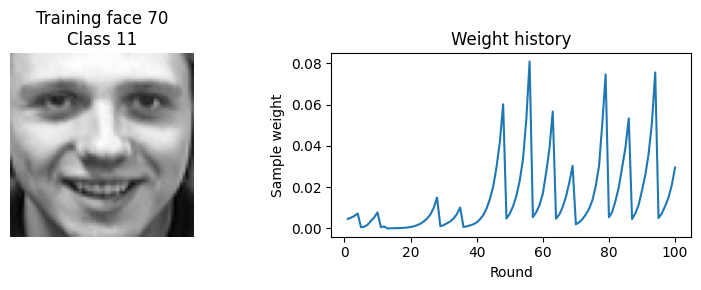

In [90]:
#face prediction history and plots
face_history = pd.DataFrame({
    "round": np.arange(1, len(boost_trees) + 1),
    "prediction": prediction_history[:, face_id],
    "correct": prediction_history[:, face_id] == y_train[face_id],
    "weight": weight_history[:, face_id]
})

display(face_history)

face_history.to_csv(
    "results/q2c_high_weight_face.csv",
    index=False
)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))

ax[0].imshow(X_train[face_id].reshape(64, 64), cmap="gray")
ax[0].set_title(f"Training face {face_id}\nClass {y_train[face_id]}")
ax[0].axis("off")
ax[1].plot(
    face_history["round"],
    face_history["weight"]
)
ax[1].set_xlabel("Round")
ax[1].set_ylabel("Sample weight")
ax[1].set_title("Weight history")

plt.tight_layout()
plt.savefig(
    "figures/q2c_high_weight_face.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

**Part D**

In [91]:
#boosting prediction with normalised weighted vote confidence
def boost_predict_conf(X):

    scores = np.zeros((len(X), 40))
    for tree, alpha in zip(boost_trees, boost_alphas):
        pred = tree.predict(X)
        scores[np.arange(len(X)), pred] += alpha
    pred = np.argmax(scores, axis=1)
    conf = scores.max(axis=1) / np.sum(boost_alphas)
    return pred, conf, scores


boost_clean_pred, boost_clean_conf, boost_clean_scores = boost_predict_conf(X_test)
boost_masked_pred, boost_masked_conf, boost_masked_scores = boost_predict_conf(X_test_masked)

In [92]:
#final clean v masked comparison
q2d_table = pd.DataFrame([
    ["Single Tree", "Clean", accuracy_score(y_test, tree_clean_pred), tree_clean_conf.mean()],
    ["Single Tree", "Masked", accuracy_score(y_test, tree_masked_pred), tree_masked_conf.mean()],

    ["Bagging", "Clean", accuracy_score(y_test, bag_clean_pred), bag_clean_conf.mean()],
    ["Bagging", "Masked", accuracy_score(y_test, bag_masked_pred), bag_masked_conf.mean()],

    ["Boosting", "Clean", accuracy_score(y_test, boost_clean_pred), boost_clean_conf.mean()],
    ["Boosting", "Masked", accuracy_score(y_test, boost_masked_pred), boost_masked_conf.mean()]
],
columns=["model", "test_set", "accuracy", "mean_confidence"])

display(q2d_table)
q2d_table.to_csv(
    "results/q2d_clean_masked_comparison.csv",
    index=False
)

,model,test_set,accuracy,mean_confidence
0,Single Tree,Clean,0.6875,1.000000
1,Single Tree,Masked,0.3375,1.000000
2,Bagging,Clean,0.8625,0.417750
3,Bagging,Masked,0.5625,0.312000
4,Boosting,Clean,0.4625,0.119061
5,Boosting,Masked,0.4500,0.112245


In [93]:
#finding face where baggin and boosting react differntly

both_clean_correct = (
    (bag_clean_pred == y_test) &
    (boost_clean_pred == y_test)
)

different_masked = (
    (bag_masked_pred == y_test) !=
    (boost_masked_pred == y_test)
)

cases = np.where(both_clean_correct & different_masked)[0]

if len(cases) == 0:
    cases = np.where(bag_masked_pred != boost_masked_pred)[0]

face = cases[0]

print("Test index:", face)
print("True class:", y_test[face])

print("Bagging clean/masked:",
      bag_clean_pred[face], bag_masked_pred[face])
print("Boosting clean/masked:",
      boost_clean_pred[face], boost_masked_pred[face])

Test index: 18
True class: 9
Bagging clean/masked: 9 35
Boosting clean/masked: 9 9


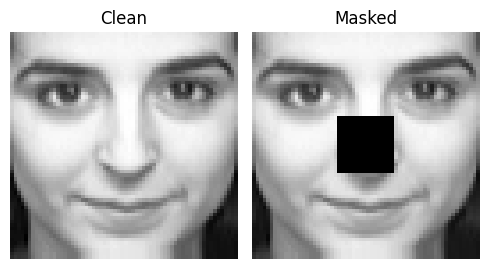

Bagging
Clean prediction : 9
Masked prediction: 35
Clean winning votes : 43 / 200
Masked winning votes: 40 / 200
Clean confidence : 0.215
Masked confidence: 0.2

bnagging pairwise disagreement
Clean : 0.9034
Masked: 0.8905

Boosting
Clean prediction : 9
Masked prediction: 9
Clean confidence : 0.1654
Masked confidence: 0.1547

boosting sample weighting for the class 9
Training indices: [54 55 56 57 58 59]
Maximum total class weight 0.0753
Round of maximum weight 30


In [96]:
# selected face analysis showing clean and masked versions of the face
fig, ax = plt.subplots(1, 2, figsize=(5, 3))

ax[0].imshow(X_test[face].reshape(64, 64), cmap="gray")
ax[0].set_title("Clean")
ax[0].axis("off")
ax[1].imshow(X_test_masked[face].reshape(64, 64), cmap="gray")
ax[1].set_title("Masked")
ax[1].axis("off")
plt.tight_layout()
plt.savefig("figures/q2d_different_response.png", dpi=200)
plt.show()


# bagging results
print("Bagging")
print("Clean prediction :", bag_clean_pred[face])
print("Masked prediction:", bag_masked_pred[face])
print("Clean winning votes :", bag_clean_votes[face].max(), "/", final_B)
print("Masked winning votes:", bag_masked_votes[face].max(), "/", final_B)
print("Clean confidence :", round(bag_clean_conf[face], 4))
print("Masked confidence:", round(bag_masked_conf[face], 4))

# pairwise disagreement among the bagging trees
def face_disagreement(votes):
    B = votes.sum()
    agreement = np.sum(votes * (votes - 1)) / (B * (B - 1))
    return 1 - agreement

print("\nbnagging pairwise disagreement")
print("Clean :", round(face_disagreement(bag_clean_votes[face]), 4))
print("Masked:", round(face_disagreement(bag_masked_votes[face]), 4))

# boosting results
print("\nBoosting")
print("Clean prediction :", boost_clean_pred[face])
print("Masked prediction:", boost_masked_pred[face])
print("Clean confidence :", round(boost_clean_conf[face], 4))
print("Masked confidence:", round(boost_masked_conf[face], 4))


# weight carried by training images of the same class
same_class = np.where(y_train == y_test[face])[0]
class_weights = weight_history[:, same_class].sum(axis=1)
print("\nboosting sample weighting for the class", y_test[face])
print("Training indices:", same_class)
print("Maximum total class weight", round(class_weights.max(), 4))
print("Round of maximum weight", np.argmax(class_weights) + 1)

**Question 3: Bias and variance as measured quantities**

**Part a**

In [97]:
#one compelte refit
from joblib import Parallel, delayed

def one_refit(r):

    rng_r = np.random.default_rng(seed + r)

    # 6 samples with replacement from each identity
    ids = []
    for c in range(40):
        class_ids = np.where(y_train == c)[0]
        ids.extend(rng_r.choice(class_ids, 6, replace=True))

    Xr = X_train[ids]
    yr = y_train[ids]


    # single tree
    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed + r
    )
    tree.fit(Xr, yr)

    p_tree = tree.predict_proba(X_test)
    acc_tree = accuracy_score(y_test, np.argmax(p_tree, axis=1))


    # bagging
    bag_scores = np.zeros((len(X_test), 40))
    bag_rng = np.random.default_rng(seed + 1000 + r)

    for b in range(final_B):
        boot = bag_rng.choice(len(Xr), len(Xr), replace=True)

        t = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_min_leaf,
            random_state=seed + b
        )
        t.fit(Xr[boot], yr[boot])
        pred = t.predict(X_test)
        bag_scores[np.arange(len(X_test)), pred] += 1

    p_bag = bag_scores / final_B
    acc_bag = accuracy_score(y_test, np.argmax(p_bag, axis=1))


    # boosting
    weights = np.ones(len(Xr)) / len(Xr)
    boost_scores = np.zeros((len(X_test), 40))
    alpha_sum = 0
    for t in range(best_boost_rounds):

        model = DecisionTreeClassifier(
            max_depth=best_boost_depth,
            random_state=seed + t
        )

        model.fit(Xr, yr, sample_weight=weights)
        pred_train = model.predict(Xr)
        wrong = pred_train != yr
        error = np.sum(weights[wrong])

        if error >= 1 - 1/40:
            break

        error = max(error, 1e-12)
        alpha = np.log((1-error)/error) + np.log(39)

        weights *= np.exp(alpha * wrong)
        weights /= weights.sum()

        pred_test = model.predict(X_test)
        boost_scores[np.arange(len(X_test)), pred_test] += alpha
        alpha_sum += alpha

    p_boost = boost_scores / alpha_sum
    acc_boost = accuracy_score(y_test, np.argmax(p_boost, axis=1))
    return p_tree, p_bag, p_boost, acc_tree, acc_bag, acc_boost

In [99]:
#running the 30 repetitions
runs = Parallel(n_jobs=-1)(
    delayed(one_refit)(r) for r in range(30)
)
tree_p = np.array([x[0] for x in runs])
bag_p = np.array([x[1] for x in runs])
boost_p = np.array([x[2] for x in runs])
tree_acc = np.array([x[3] for x in runs])
bag_acc = np.array([x[4] for x in runs])
boost_acc = np.array([x[5] for x in runs])

print("30 refits completed.")

30 refits completed.


In [100]:
#defining bias squared and variance
target = np.eye(40)[y_test]

def bias_variance(P):

    mean_p = P.mean(axis=0)

    bias2 = np.mean(
        np.sum((mean_p - target) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum((P - mean_p) ** 2, axis=2)
    )

    return bias2, variance

tree_bias, tree_var = bias_variance(tree_p)
bag_bias, bag_var = bias_variance(bag_p)
boost_bias, boost_var = bias_variance(boost_p)

#final table and logging the results

q3a_table = pd.DataFrame([
    ["Single Tree", tree_bias, tree_var, tree_acc.mean(), tree_acc.std()],
    ["Bagging", bag_bias, bag_var, bag_acc.mean(), bag_acc.std()],
    ["Boosting", boost_bias, boost_var, boost_acc.mean(), boost_acc.std()]
],
columns=[
    "model",
    "bias_squared",
    "variance",
    "mean_test_accuracy",
    "std_test_accuracy"
])

display(q3a_table)

q3a_table.to_csv(
    "results/q3a_bias_variance.csv",
    index=False
)

pd.DataFrame({
    "refit": np.arange(1, 31),
    "single_tree": tree_acc,
    "bagging": bag_acc,
    "boosting": boost_acc
}).to_csv(
    "results/q3a_refit_accuracies.csv",
    index=False
)

,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,Single Tree,0.357944,0.628722,0.506667,0.057349
1,Bagging,0.488806,0.021449,0.798750,0.045569
2,Boosting,0.882917,0.017764,0.296667,0.074157


**Part B**

In [101]:
#choosing depth
selected_depth = frozen_tree.get_depth()

shallow_depth = 2
deep_depth = selected_depth + 8

depth_values = [shallow_depth, selected_depth, deep_depth]

print("Shallow depth :", shallow_depth)
print("Selected depth:", selected_depth)
print("Deep depth    :", deep_depth)

Shallow depth : 2
Selected depth: 38
Deep depth    : 46


In [102]:
#one repeition for one depth
def depth_refit(r, depth):

    rng_r = np.random.default_rng(seed + r)

    ids = []
    for c in range(40):
        class_ids = np.where(y_train == c)[0]
        ids.extend(rng_r.choice(class_ids, 6, replace=True))

    Xr = X_train[ids]
    yr = y_train[ids]

    #single tree
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed + r
    )
    tree.fit(Xr, yr)
    p_tree = tree.predict_proba(X_test)

    #100tree bagging
    scores = np.zeros((len(X_test), 40))
    rng_bag = np.random.default_rng(seed + 1000 + r)

    for b in range(100):

        boot = rng_bag.choice(len(Xr), len(Xr), replace=True)

        t = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_min_leaf,
            random_state=seed + b
        )

        t.fit(Xr[boot], yr[boot])

        pred = t.predict(X_test)
        scores[np.arange(len(X_test)), pred] += 1

    p_bag = scores / 100

    return p_tree, p_bag

In [103]:
depth_runs = Parallel(n_jobs=8)(
    delayed(depth_refit)(r, depth)
    for depth in depth_values
    for r in range(30)
)

In [104]:
q3b_results = []

k = 0

for depth in depth_values:
    tree_probs = []
    bag_probs = []

    for r in range(30):
        tree_probs.append(depth_runs[k][0])
        bag_probs.append(depth_runs[k][1])
        k += 1

    tree_probs = np.array(tree_probs)
    bag_probs = np.array(bag_probs)
    tree_bias, tree_var = bias_variance(tree_probs)
    bag_bias, bag_var = bias_variance(bag_probs)
    reduction = 100 * (tree_var - bag_var) / tree_var

    q3b_results.append([
        depth,
        tree_bias,
        tree_var,
        bag_bias,
        bag_var,
        reduction
    ])

#final table and saving the results
q3b_table = pd.DataFrame(
    q3b_results,
    columns=[
        "depth",
        "tree_bias_squared",
        "tree_variance",
        "bagging_bias_squared",
        "bagging_variance",
        "variance_reduction_percent"
    ]
)

display(q3b_table)
q3b_table.to_csv(
    "results/q3b_depth_bias_variance.csv",
    index=False
)

,depth,tree_bias_squared,tree_variance,bagging_bias_squared,bagging_variance,variance_reduction_percent
0,2,0.916260,0.035070,0.928437,0.010899,68.923094
1,38,0.357944,0.628722,0.490710,0.025267,95.981172
2,46,0.357944,0.628722,0.489558,0.025259,95.982497


**Part C**

In [105]:
#accuracy gain and disagreeemnt 
q3c_rows = []

for i, depth in enumerate(depth_values):

    runs_d = depth_runs[i*30:(i+1)*30]

    tree_acc_d = []
    bag_acc_d = []
    disagreement_d = []

    for p_tree, p_bag in runs_d:

        tree_acc_d.append(
            accuracy_score(y_test, np.argmax(p_tree, axis=1))
        )

        bag_acc_d.append(
            accuracy_score(y_test, np.argmax(p_bag, axis=1))
        )

        votes = np.rint(p_bag * 100).astype(int)

        dis = 1 - np.sum(
            votes * (votes - 1), axis=1
        ) / (100 * 99)

        disagreement_d.append(dis.mean())

    q3c_rows.append([
        depth,
        np.mean(tree_acc_d),
        np.mean(bag_acc_d),
        np.mean(bag_acc_d) - np.mean(tree_acc_d),
        np.mean(disagreement_d)
    ])

In [106]:
#measuring leaf occupancy
leaf_results = []

for depth in depth_values:

    mean_leaf_list = []
    single_leaf_list = []

    for r in range(30):

        rng_r = np.random.default_rng(seed + r)

        ids = []
        for c in range(40):
            class_ids = np.where(y_train == c)[0]
            ids.extend(rng_r.choice(class_ids, 6, replace=True))

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_min_leaf,
            random_state=seed + r
        )
        tree.fit(X_train[ids], y_train[ids])
        leaves = np.where(tree.tree_.children_left == -1)[0]
        samples = tree.tree_.n_node_samples[leaves]
        mean_leaf_list.append(samples.mean())
        single_leaf_list.append(np.mean(samples == 1))

    leaf_results.append([
        depth,
        np.mean(mean_leaf_list),
        np.mean(single_leaf_list)
    ])

In [107]:
#final table 

q3c_table = pd.DataFrame(
    q3c_rows,
    columns=[
        "depth",
        "tree_accuracy",
        "bagging_accuracy",
        "accuracy_gain",
        "bagging_disagreement"
    ]
)

leaf_table = pd.DataFrame(
    leaf_results,
    columns=[
        "depth",
        "mean_samples_per_leaf",
        "single_sample_leaf_fraction"
    ]
)

In [108]:
q3c_table = q3c_table.merge(leaf_table, on="depth")

display(q3c_table)

q3c_table.to_csv(
    "results/q3c_depth_improvement.csv",
    index=False
)

,depth,tree_accuracy,bagging_accuracy,accuracy_gain,bagging_disagreement,mean_samples_per_leaf,single_sample_leaf_fraction
0,2,0.058750,0.156250,0.097500,0.961168,78.666667,0.0
1,38,0.506667,0.785417,0.278750,0.810822,6.000000,0.0
2,46,0.506667,0.785833,0.279167,0.810184,6.000000,0.0


In [110]:
tree_row = q3a_table[q3a_table["model"] == "Single Tree"].iloc[0]
bag_row = q3a_table[q3a_table["model"] == "Bagging"].iloc[0]
boost_row = q3a_table[q3a_table["model"] == "Boosting"].iloc[0]

q3d_table = pd.DataFrame([
    ["Single Tree",
     accuracy_score(y_test, tree_clean_pred),
     accuracy_score(y_test, tree_masked_pred),
     tree_row["bias_squared"],
     tree_row["variance"]],

    ["Bagging",
     accuracy_score(y_test, bag_clean_pred),
     accuracy_score(y_test, bag_masked_pred),
     bag_row["bias_squared"],
     bag_row["variance"]],

    ["Boosting",
     accuracy_score(y_test, boost_clean_pred),
     accuracy_score(y_test, boost_masked_pred),
     boost_row["bias_squared"],
     boost_row["variance"]]
],
columns=[
    "model",
    "clean_accuracy",
    "masked_accuracy",
    "bias_squared",
    "variance"
])

display(q3d_table)

q3d_table.to_csv(
    "results/q3d_final_summary.csv",
    index=False
)

,model,clean_accuracy,masked_accuracy,bias_squared,variance
0,Single Tree,0.6875,0.3375,0.357944,0.628722
1,Bagging,0.8625,0.5625,0.488806,0.021449
2,Boosting,0.4625,0.4500,0.882917,0.017764
